# Aula 13 — Inferência estatística, testes de hipótese e intervalos de confiança
**Fund. de Programação, Dados e Estatística para IA**

Notebook de acompanhamento dos slides. A ordem das seções segue a aula:

0. Revisão da Aula 12
1. A lógica da inferência: variabilidade amostral e valor-p (moeda)
2. Intervalos de confiança
3. Testes: Welch, Mann–Whitney e qui-quadrado
4. Limites: muitos testes

> Objetivo: passar da descrição da amostra para uma análise que reconheça a incerteza da amostragem, sem transformar valor-p em sinônimo de verdade.

In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="talk")

## Carregar a base do caso-guia
Use a base de readmissão tratada nas aulas anteriores. **Ajuste o caminho do arquivo.**
Colunas usadas hoje: `idade`, `tempo_internacao_dias`, `readmissao_30d` (0/1) e `servico`.

In [52]:
df = pd.read_csv("pacientes_aula8_analise.csv")

colunas = ["idade", "tempo_internacao_dias", "readmissao_30d", "servico"]
print(df.shape)
df[colunas].isna().sum()   # valores ausentes: unidade de análise e ausentes antes de qualquer teste

(320, 7)


,0
idade,6
tempo_internacao_dias,12
readmissao_30d,0
servico,0


## 1. A lógica da inferência

### Variabilidade amostral: mesma população, médias diferentes
A população simulada não muda; o que muda é a amostra sorteada.

In [53]:
rng = np.random.default_rng(42)

populacao_simulada = rng.normal(loc=60, scale=12, size=100000)

medias = []
for _ in range(200):
    amostra = rng.choice(populacao_simulada, size=30, replace=False)
    medias.append(amostra.mean())

print("Média da população simulada:", populacao_simulada.mean())
print("Menor média amostral:", min(medias))
print("Maior média amostral:", max(medias))

Média da população simulada: 59.949204836652925
Menor média amostral: 54.30124424109912
Maior média amostral: 66.64780200112892


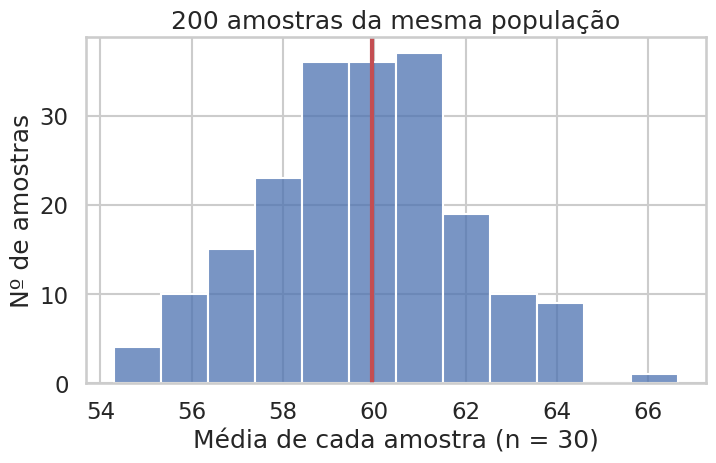

In [54]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(medias, binwidth=1, ax=ax)
ax.axvline(populacao_simulada.mean(), color="#c44e52", lw=3)
ax.set(xlabel="Média de cada amostra (n = 30)", ylabel="Nº de amostras",
       title="200 amostras da mesma população");

### Hipóteses e nível de significância
- **H0:** hipótese de referência (ex.: as médias populacionais de idade são iguais nos dois grupos).
- **H1:** alternativa (ex.: são diferentes — teste bilateral).
- **α = 0,05** é definido **antes** de olhar o resultado.

### Valor-p na prática: a moeda é honesta?
H0: moeda honesta (50% cara). H1: moeda viciada (bilateral). Jogamos 6 vezes: 6 caras.

In [55]:
from math import comb

n = 6
probs = pd.Series({k: comb(n, k) / 2**n for k in range(n + 1)}, name="P(k caras)")
print(probs.mul(64).astype(int).astype(str) + "/64")

# "tão extremo ou mais": 6 caras OU 0 caras (bilateral)
p = probs[6] + probs[0]
print(f"p = {p:.4f}")

0     1/64
1     6/64
2    15/64
3    20/64
4    15/64
5     6/64
6     1/64
Name: P(k caras), dtype: object
p = 0.0312


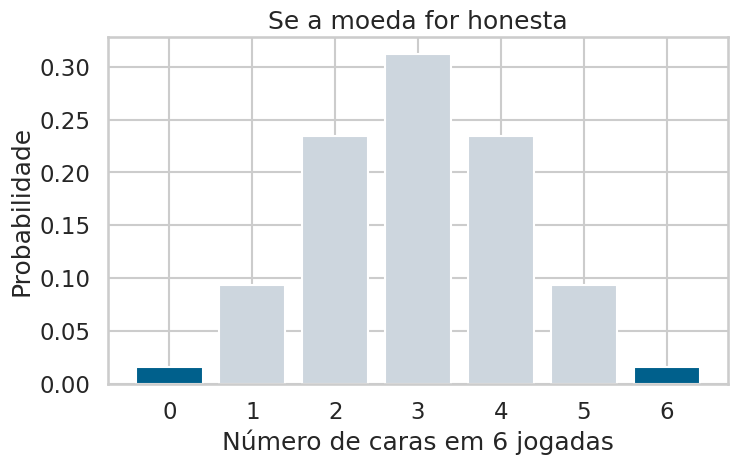

In [56]:
cores = ["#00608C" if k in (0, 6) else "#CDD6DE" for k in probs.index]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(probs.index, probs.values, color=cores)
ax.set(xlabel="Número de caras em 6 jogadas", ylabel="Probabilidade",
       title="Se a moeda for honesta");

In [57]:
# O mesmo cálculo com o scipy
print(stats.binomtest(6, n=6, p=0.5, alternative="two-sided").pvalue)

# Com 5 jogadas, mesmo 5 caras não basta para rejeitar H0 com α = 0,05
print(stats.binomtest(5, n=5, p=0.5, alternative="two-sided").pvalue)

0.03125
0.0625


**Leitura:** p ≈ 0,031 < 0,05 → rejeitamos H0. Se a moeda fosse honesta, um resultado tão extremo apareceria em cerca de 3% das vezes.
O valor-p **não** é a probabilidade de H0 ser verdadeira.

## 2. Intervalos de confiança
**estimativa pontual ± margem de incerteza.** Se repetíssemos a amostragem muitas vezes, cerca de 95% dos intervalos construídos assim conteriam o parâmetro verdadeiro.

### IC95% para uma média

In [58]:
x = df["tempo_internacao_dias"].dropna()
media = x.mean()
erro_padrao = stats.sem(x)          # erro-padrão da média

ic95 = stats.t.interval(
    confidence=0.95,
    df=len(x) - 1,
    loc=media,
    scale=erro_padrao
)
print("Média:", media)
print("IC95%:", ic95)

Média: 6.8019480519480515
IC95%: (np.float64(6.161752545051017), np.float64(7.442143558845086))


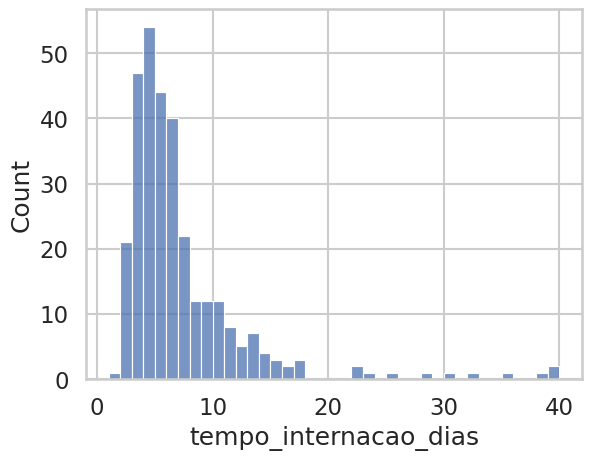

In [59]:
# Antes de interpretar: olhe a distribuição
sns.histplot(x, binwidth=1);

### Mesma estimativa, precisões diferentes (exemplo conceitual)

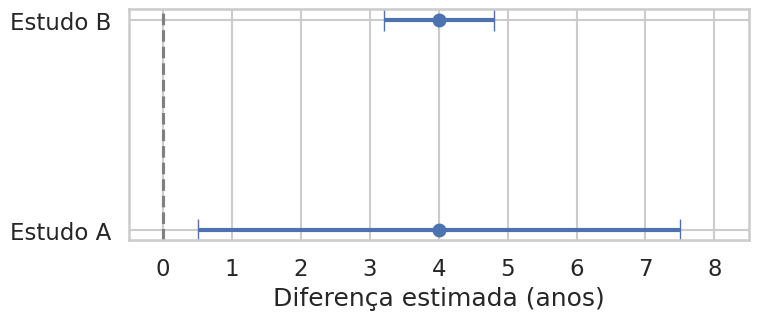

In [60]:
estudos = pd.DataFrame({
    "estudo": ["Estudo A", "Estudo B"],
    "estimativa": [4, 4],
    "li": [0.5, 3.2],
    "ls": [7.5, 4.8],
})
fig, ax = plt.subplots(figsize=(8, 3))
ax.errorbar(estudos["estimativa"], estudos["estudo"],
            xerr=[estudos["estimativa"] - estudos["li"],
                  estudos["ls"] - estudos["estimativa"]],
            fmt="o", capsize=8, lw=3)
ax.axvline(0, ls="--", color="gray")
ax.set(xlabel="Diferença estimada (anos)", xlim=(-0.5, 8.5));

## 3. Testes para dois grupos e para categorias
O nome do teste vem **depois** da pergunta e do tipo de dado.

### Teste t de Welch — a idade média difere entre pacientes com e sem readmissão?

In [61]:
grupo_nao = df.loc[df["readmissao_30d"] == 0, "idade"].dropna()
grupo_sim = df.loc[df["readmissao_30d"] == 1, "idade"].dropna()

resultado_t = stats.ttest_ind(grupo_nao, grupo_sim,
                              equal_var=False,          # versão de Welch
                              alternative="two-sided")

print("Média sem readmissão:", grupo_nao.mean())
print("Média com readmissão:", grupo_sim.mean())
print("Diferença observada:", grupo_sim.mean() - grupo_nao.mean())
print(resultado_t)

Média sem readmissão: 58.885714285714286
Média com readmissão: 69.55882352941177
Diferença observada: 10.673109243697482
TtestResult(statistic=np.float64(-4.339108456066028), pvalue=np.float64(7.636708917011747e-05), df=np.float64(46.53640007478383))


**Forma adequada de falar:** “Os dados apresentam [ou não] evidência contra a hipótese de igualdade das médias, segundo o teste de Welch e o nível de significância definido.”
Depois do valor-p: qual foi a diferença? Qual a sua incerteza? Essa magnitude importa?

### Mann–Whitney — tempo de internação (variável assimétrica)

In [62]:
tempo_nao = df.loc[df["readmissao_30d"] == 0, "tempo_internacao_dias"].dropna()
tempo_sim = df.loc[df["readmissao_30d"] == 1, "tempo_internacao_dias"].dropna()

resultado_u = stats.mannwhitneyu(tempo_nao, tempo_sim,
                                 alternative="two-sided",
                                 method="auto")

print("Mediana sem readmissão:", tempo_nao.median())
print("Mediana com readmissão:", tempo_sim.median())
print(resultado_u)

Mediana sem readmissão: 5.0
Mediana com readmissão: 6.0
MannwhitneyuResult(statistic=np.float64(4101.0), pvalue=np.float64(0.2522921919813279))


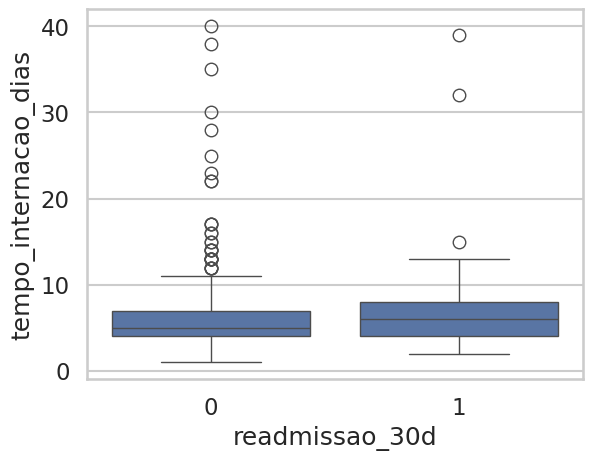

In [63]:
# Descrição complementar: forma das duas distribuições
sns.boxplot(data=df, x="readmissao_30d", y="tempo_internacao_dias");

Mann–Whitney usa a ordenação (postos): **não** é automaticamente um “teste de medianas”.

### Qui-quadrado — serviço e readmissão estão associados?

In [64]:
tabela = pd.crosstab(df["servico"], df["readmissao_30d"])
chi2, p, dof, esperados = stats.chi2_contingency(tabela)

print(tabela)
print("Qui-quadrado:", chi2)
print("Valor-p:", p)

readmissao_30d   0   1
servico               
Cardiologia     71   2
Clínica Médica  81  13
Neurologia      37   7
Oncologia       44   7
Ortopedia       53   5
Qui-quadrado: 7.8518814232847225
Valor-p: 0.09715715587989514


In [65]:
# Inspecionar as frequências esperadas sob independência
esperados_df = pd.DataFrame(
    esperados,
    index=tabela.index,
    columns=tabela.columns
)
esperados_df.round(1)

readmissao_30d,0,1
servico,,
Cardiologia,65.2,7.8
Clínica Médica,84.0,10.0
Neurologia,39.3,4.7
Oncologia,45.6,5.4
Ortopedia,51.8,6.2


Esperadas muito pequenas tornam a aproximação inadequada (em tabelas 2×2 com contagens pequenas, considere métodos exatos).
Um resultado significativo indica evidência contra independência — **não** causalidade.

## 4. O problema de muitos testes
Com 20 testes independentes e todas as H0 verdadeiras, qual a chance de ao menos um p < 0,05?

In [66]:
k = 20
print(f"{1 - 0.95**k:.0%}")

64%


In [67]:
# Simulação: 20 testes t entre grupos que vêm da MESMA população
rng = np.random.default_rng(1)
ps = [stats.ttest_ind(rng.normal(size=30), rng.normal(size=30)).pvalue
      for _ in range(20)]
print("Testes com p < 0,05:", sum(p < 0.05 for p in ps), "de", len(ps))

Testes com p < 0,05: 1 de 20
